# 03 — UMAP Analysis

## Objective

Visualize the nanoparticle formulation design space in two dimensions using the numerical features generated by the feature-engineering notebook.

## Main tasks

1. Load and validate processed formulation features
2. Select the full or property-based feature set
3. Prepare formulation labels for plot coloring
4. Calculate a two-dimensional UMAP embedding
5. Evaluate local neighborhood preservation
6. Generate individual and overview plots
7. Export embedding coordinates, figures, and analysis settings
8. Create an interactive plot and optionally compare UMAP parameters


## Set up the analysis

Install the required packages if needed and configure the feature set, UMAP parameters, and project directories.

Place this notebook in `notebooks/` and the processed CSV in `data/processed/`. The input search also supports a CSV stored alongside the notebook or in the project root. The combined `formulation_features_chemical.csv` is accepted when the selected feature-table filename is unavailable.


In [21]:
from pathlib import Path
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import umap
except ImportError as exc:
    raise ImportError("Install umap-learn in this notebook's kernel: %pip install umap-learn") from exc
from sklearn.manifold import trustworthiness

FEATURE_SET = "property_based"  # or "full"
RANDOM_STATE = 42
N_NEIGHBORS = 15
MIN_DIST = 1.4
SPREAD = 1.5
METRIC = "euclidean"

# Works from project root or notebooks/. Set manually if your layout differs.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT.parent / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_FILES = {
    "property_based": "formulation_features_property_based.csv",
    "full": "formulation_features_chemical_full.csv",
}
# Prefer the intended feature table; accept the uploaded combined chemical table.
candidates = [
    PROCESSED_DIR / FEATURE_FILES[FEATURE_SET],
    PROCESSED_DIR / "formulation_features_chemical.csv",
    PROJECT_ROOT / FEATURE_FILES[FEATURE_SET],
    PROJECT_ROOT / "formulation_features_chemical.csv",
    Path.cwd() / "formulation_features_chemical.csv",
    PROJECT_ROOT / "upload" / "formulation_features_chemical.csv",
]
FEATURE_FILE = next((p for p in candidates if p.is_file()), candidates[0])
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "Dataset.csv"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "umap" / FEATURE_SET
RESULT_DIR = PROJECT_ROOT / "results" / "umap" / FEATURE_SET
for directory in [FIGURE_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print("Input:", FEATURE_FILE)


Input: C:\Users\洪家賢\Documents\AI Research\Nanoparticle-AI-Optimization\data\processed\formulation_features_property_based.csv


## Load and validate formulation features

Load the processed feature table and check for missing values, nonnumeric entries, infinite values, and duplicate formulation IDs.

The **property-based feature set** removes Carrier 1 and Carrier 2 identity one-hot columns while retaining material properties, chemical descriptors, glucan variables, and formulation ratios. The **full feature set** retains all available features.

Features are already scaled by the feature-engineering notebook. Constant columns are removed, and `ID` is excluded from the embedding. Duplicate feature vectors with different IDs are retained and reported.

Carrier molecular weights and family assignments should be checked against the material specifications in the upstream notebook. This analysis uses the supplied feature values without correcting material information.


In [22]:
if not FEATURE_FILE.is_file():
    raise FileNotFoundError(f"Run notebook 02 first to generate: {FEATURE_FILE}")
features = pd.read_csv(FEATURE_FILE, dtype={"ID": "string"})
features = features.loc[:, ~features.columns.str.startswith("Unnamed")]
if "ID" not in features or features["ID"].isna().any() or features["ID"].duplicated().any():
    raise ValueError("ID must exist, be nonmissing, and be unique.")
X = features.drop(columns="ID").apply(pd.to_numeric, errors="raise")
if X.empty or not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Feature matrix must contain finite numeric values without missing entries.")
carrier_identity_cols = [c for c in X if c.startswith(("cat__Carrier 1_", "cat__Carrier 2 (NH2)_"))]
removed_identity_cols = carrier_identity_cols if FEATURE_SET == "property_based" else []
X = X.drop(columns=removed_identity_cols)
print("Removed carrier identity columns:", len(removed_identity_cols))
constant_cols = X.columns[X.nunique() <= 1].tolist()
X = X.drop(columns=constant_cols)
if X.shape[1] == 0 or len(X) < 4 or len(X.drop_duplicates()) < 3:
    raise ValueError("Need at least 4 rows, 3 distinct feature vectors, and a nonconstant feature.")
print("Samples / features:", X.shape)
print("Removed constant columns:", constant_cols)
print("Duplicate feature vectors:", X.duplicated().sum())
display(X.head())


Removed carrier identity columns: 0
Samples / features: (6575, 41)
Removed constant columns: ['C1_NH2', 'C1_Carrier_Family_Poloxamer']
Duplicate feature vectors: 0


,cat__Glucan Type_Barley Glucan,cat__Glucan Type_Blank NP,cat__Glucan Type_Curdlan,cat__Glucan Type_Yeast Glucan,cat__Modification_H2O2 oxidation,cat__Modification_None,cat__Modification_Succinic anhydride modification,cat__Glucan MW_High,cat__Glucan MW_Low,cat__Glucan MW_Medium,...,C2_NH2,C1_Carrier_Family_Lipid,C1_Carrier_Family_PCL,C1_Carrier_Family_PLA,C1_Carrier_Family_PLGA,C2_Carrier_Family_Lipid,C2_Carrier_Family_PCL,C2_Carrier_Family_PLA,C2_Carrier_Family_PLGA,C2_Carrier_Family_Poloxamer
0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Prepare formulation labels

Merge available labels from `Dataset.csv` by formulation ID while preserving the feature-table row order. These labels are used for plot coloring.

When the raw dataset is unavailable, recover categorical labels from the one-hot columns. Standardized ratio features are explicitly labeled as **z-scores** when their original values are unavailable.


In [23]:
metadata = features[["ID"]].copy()
label_cols = ["Glucan Type", "Modification", "Carrier 1", "Carrier 2 (NH2)",
              "Glucan MW", "Carrier 1 Mass Ratio", "Carrier 2 Mass Ratio",
              "Glucan / Carrier 2 Mass Ratio"]
if RAW_FILE.is_file():
    raw = pd.read_csv(RAW_FILE, dtype={"ID": "string"})
    if "ID" not in raw or raw["ID"].isna().any() or raw["ID"].duplicated().any():
        raise ValueError("Raw Dataset.csv needs unique nonmissing IDs for label matching.")
    available = [c for c in label_cols if c in raw]
    metadata = metadata.merge(raw[["ID"] + available], on="ID", how="left",
                              validate="one_to_one", sort=False, indicator=True)
    print("IDs without raw metadata:", (metadata["_merge"] == "left_only").sum())
    metadata = metadata.drop(columns="_merge")
else:
    print("Dataset.csv not found; recovering categorical labels from one-hot columns.")

for label in ["Glucan Type", "Modification", "Carrier 1", "Carrier 2 (NH2)", "Glucan MW"]:
    if label in metadata:
        continue
    prefix = f"cat__{label}_"
    cols = [c for c in features if c.startswith(prefix)]
    if cols:
        block = features[cols].to_numpy(dtype=float)
        if not np.isin(block, [0, 1]).all() or not np.all(block.sum(axis=1) == 1):
            raise ValueError(f"Cannot reliably decode one-hot labels: {label}")
        names = np.array([c[len(prefix):] for c in cols])
        metadata[label] = names[block.argmax(axis=1)]

numeric_plot_cols = []
for label in ["Carrier 1 Mass Ratio", "Carrier 2 Mass Ratio", "Glucan / Carrier 2 Mass Ratio"]:
    if label in metadata:
        numeric_plot_cols.append(label)
    elif f"num__{label}" in features:
        standardized_label = f"{label} (z-score)"
        metadata[standardized_label] = features[f"num__{label}"]
        numeric_plot_cols.append(standardized_label)
label_cols = [c for c in label_cols if c in metadata] + [c for c in numeric_plot_cols if c not in label_cols]
assert metadata["ID"].equals(features["ID"])
display(metadata.head())


IDs without raw metadata: 0


,ID,Glucan Type,Modification,Carrier 1,Carrier 2 (NH2),Glucan MW,Carrier 1 Mass Ratio,Carrier 2 Mass Ratio,Glucan / Carrier 2 Mass Ratio
0,YG-SA-D1-N1-R90-10-MH-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.1
1,YG-SA-D1-N1-R90-10-MH-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.8
2,YG-SA-D1-N1-R90-10-MH-G20,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,2.0
3,YG-SA-D1-N1-R90-10-MM-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.1
4,YG-SA-D1-N1-R90-10-MM-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.8


## Calculate the UMAP embedding

Reduce the selected feature matrix to two dimensions using Euclidean distance, random initialization, and a fixed random seed.

The current settings are `n_neighbors=15`, `min_dist=0.8`, and `spread=1.5`. The neighbor count is limited to the number of samples minus one. The increased `min_dist` and `spread` settings produce a more dispersed layout within groups.

**Trustworthiness** evaluates local neighborhood preservation using a reproducible subset of up to 2,000 samples. This diagnostic measures embedding quality rather than biological performance.


In [24]:
effective_neighbors = min(N_NEIGHBORS, len(X) - 1)
reducer = umap.UMAP(n_components=2, n_neighbors=effective_neighbors,
                    min_dist=MIN_DIST, spread=SPREAD, metric=METRIC, random_state=RANDOM_STATE,
                    init="random", n_jobs=1)
embedding = reducer.fit_transform(X.to_numpy(dtype=float))
if not np.isfinite(embedding).all():
    raise ValueError("UMAP generated nonfinite coordinates.")
result = metadata.copy()
result["UMAP_1"] = embedding[:, 0]
result["UMAP_2"] = embedding[:, 1]
# Bound the quadratic memory cost of the diagnostic, not the UMAP fit.
quality_indices = np.sort(np.random.default_rng(RANDOM_STATE).choice(
    len(X), size=min(2000, len(X)), replace=False))
quality_k = min(5, (len(quality_indices) - 1) // 2)
quality = trustworthiness(X.iloc[quality_indices], embedding[quality_indices],
                          n_neighbors=quality_k, metric=METRIC)
print("Trustworthiness diagnostic subset:", len(quality_indices), "rows")
print(f"Trustworthiness (k={quality_k}): {quality:.3f}")
display(result.head())


Trustworthiness diagnostic subset: 2000 rows
Trustworthiness (k=5): 0.991


,ID,Glucan Type,Modification,Carrier 1,Carrier 2 (NH2),Glucan MW,Carrier 1 Mass Ratio,Carrier 2 Mass Ratio,Glucan / Carrier 2 Mass Ratio,UMAP_1,UMAP_2
0,YG-SA-D1-N1-R90-10-MH-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.1,13.144101,9.705060
1,YG-SA-D1-N1-R90-10-MH-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.8,13.138381,8.594072
2,YG-SA-D1-N1-R90-10-MH-G20,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,2.0,1.704674,-15.841538
3,YG-SA-D1-N1-R90-10-MM-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.1,12.832203,9.160498
4,YG-SA-D1-N1-R90-10-MM-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.8,12.987355,8.810684


## Generate plots and export results

Use the same UMAP coordinates for all plots and color formulations by carrier, glucan source, modification, molecular-weight category, or formulation ratio.

Export the following files:

- **PNG and PDF figures** — individual plots with categorical or continuous coloring
- **Coordinate table** — formulation IDs, available labels, and two-dimensional UMAP coordinates
- **Analysis settings** — selected features, UMAP parameters, diagnostic results, and package versions

Individual PNG figures are saved at 300 dpi. Results are organized by feature set under `results/umap/` and `results/figures/umap/`.


In [32]:
legend_orders = {
    "Glucan Type": [
        "Yeast Glucan",
        "Barley Glucan",
        "Curdlan",
        "Blank NP",
    ],
    "Glucan MW": [
        "High",
        "Medium",
        "Low",
        "Unspecified",
    ],
    "Modification": [
        "Succinic anhydride modification",
        "H2O2 oxidation",
    ],
    "Carrier 1": [
        "D1", "D2", "D3", "D4", "D5",
    ],
    "Carrier 2 (NH2)": [
        "N1", "N2", "N3", "N4", "N5", "N6",
    ],
}
def get_legend_order(labels, column):
    present = set(labels.unique())
    preferred = legend_orders.get(column, [])

    ordered = [value for value in preferred if value in present]

    remaining = sorted(
        present - set(ordered),
        key=lambda value: str(value).casefold()
    )

    normal = [
        value for value in remaining
        if str(value).strip().casefold() not in {"none", "missing"}
    ]
    missing = [
        value for value in remaining
        if str(value).strip().casefold() == "missing"
    ]
    none = [
        value for value in remaining
        if str(value).strip().casefold() == "none"
    ]

    return ordered + normal + missing + none

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



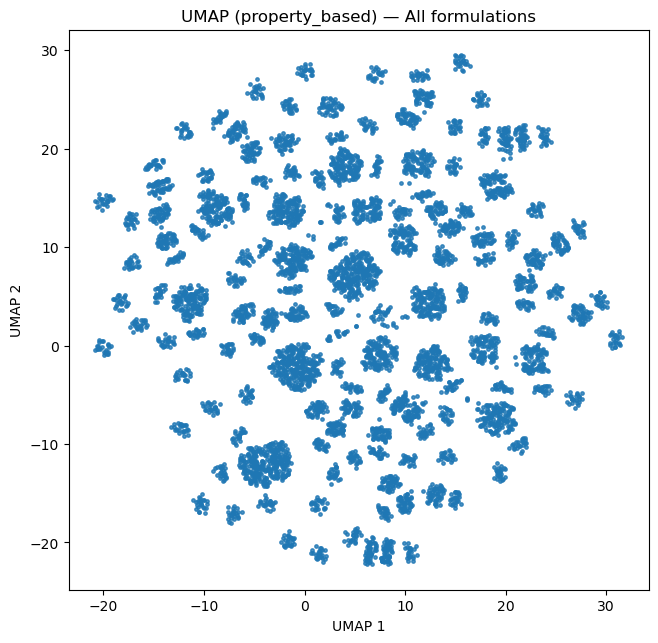

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



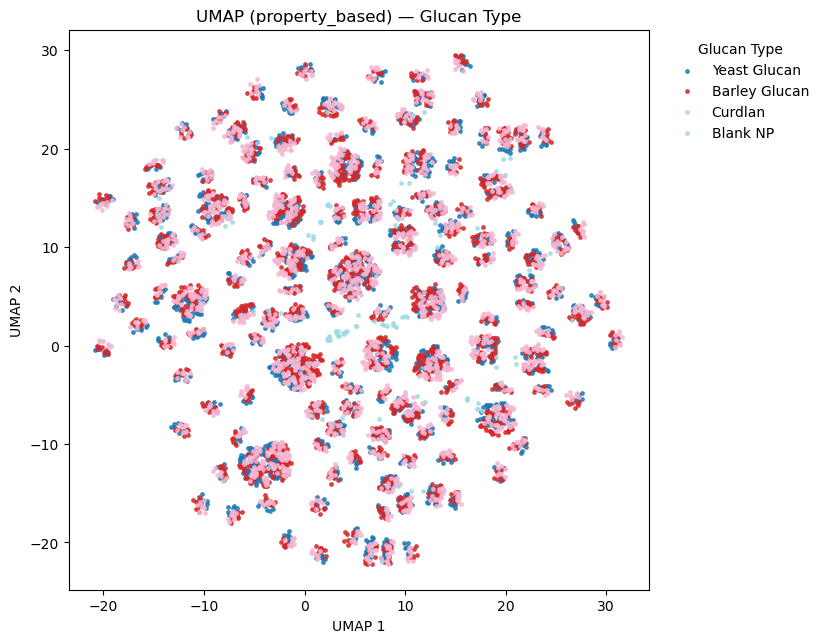

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



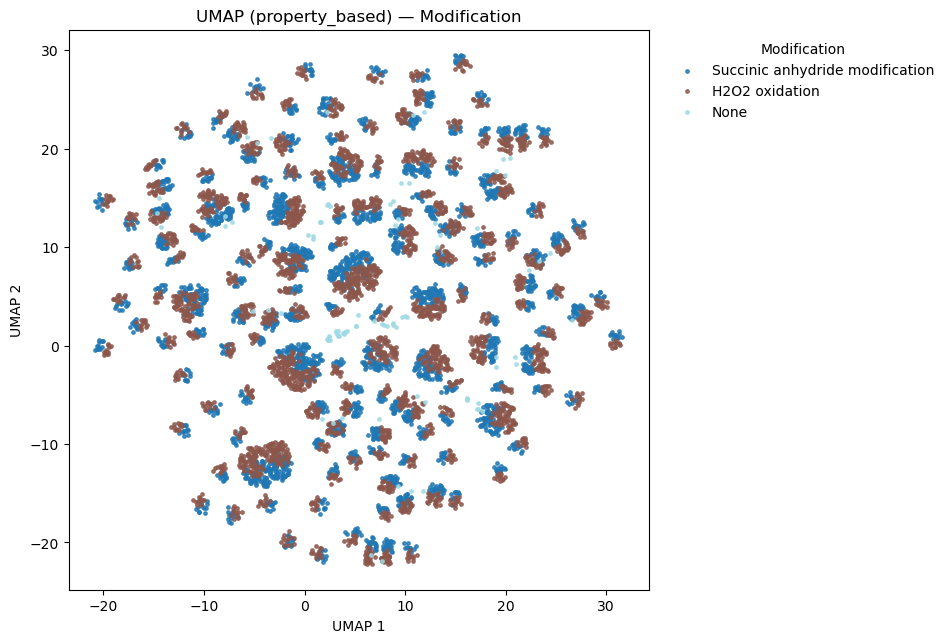

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



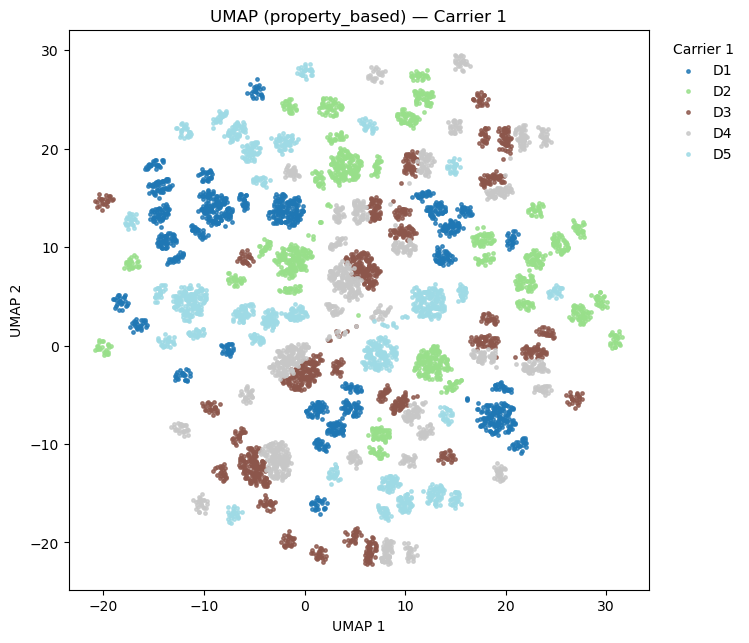

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



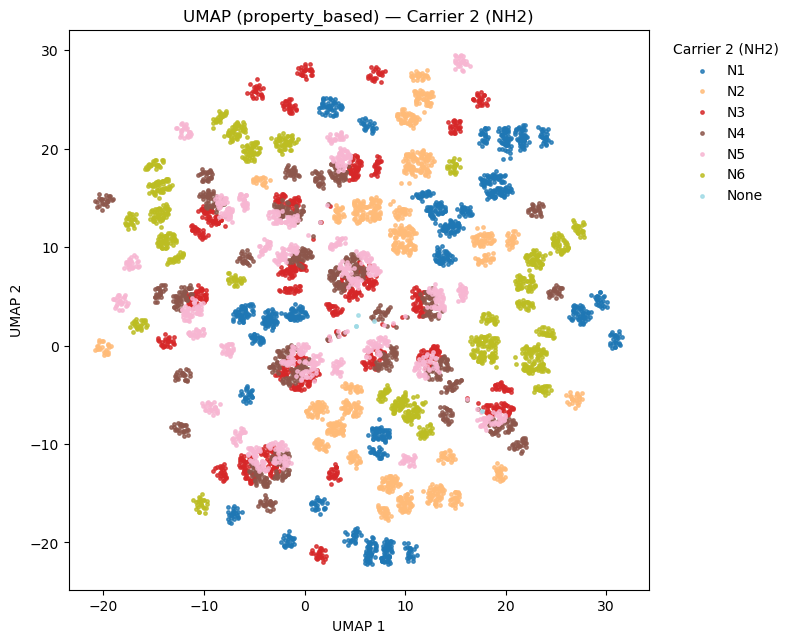

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



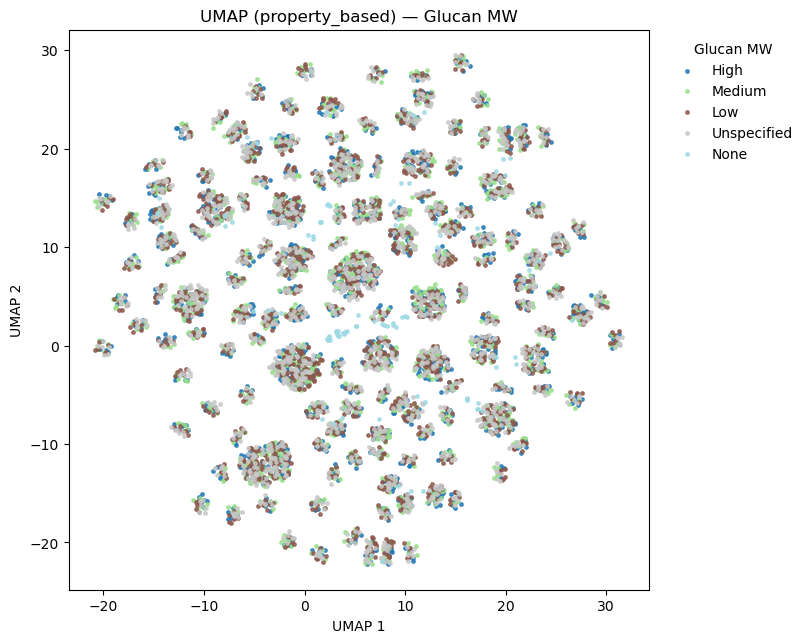

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



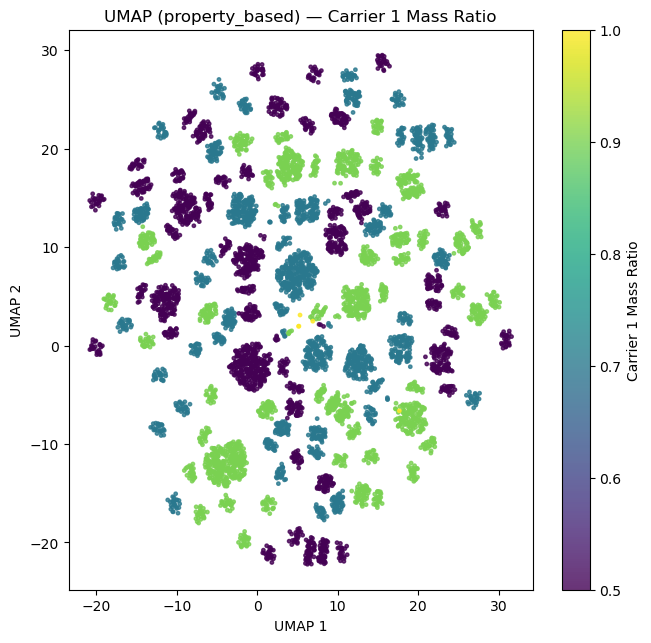

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



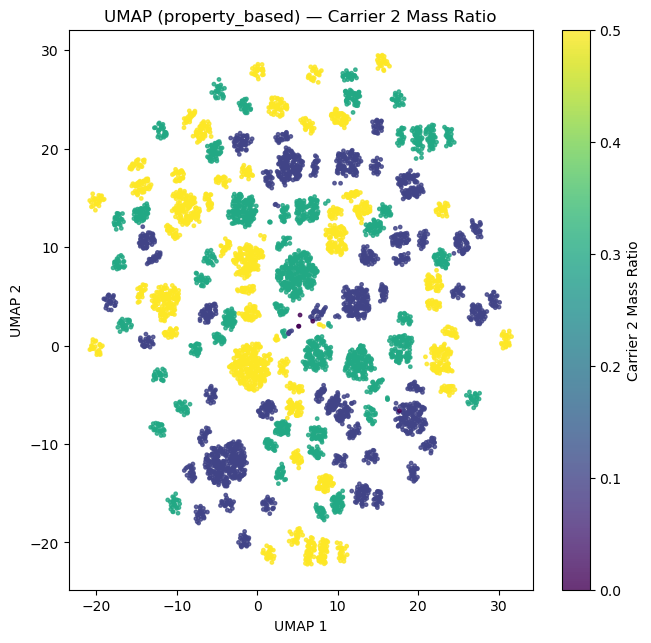

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_36856\613237807.py:28: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



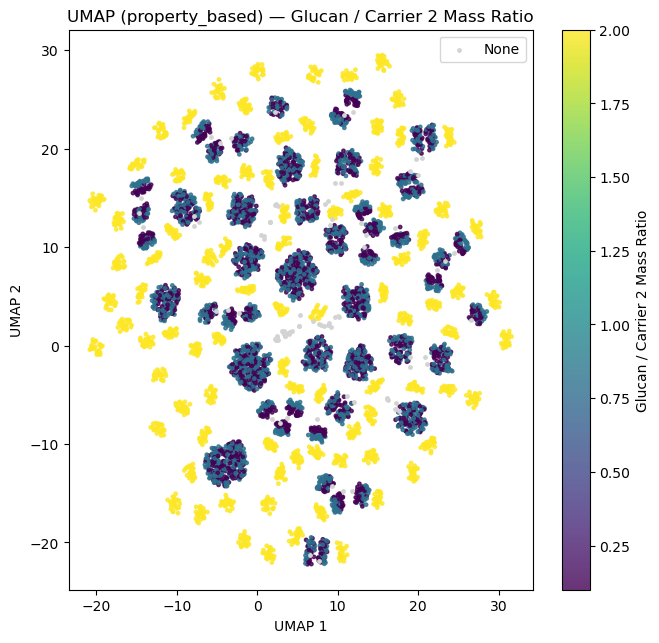

Results: C:\Users\洪家賢\Documents\AI Research\Nanoparticle-AI-Optimization\results\umap\property_based
Figures: C:\Users\洪家賢\Documents\AI Research\Nanoparticle-AI-Optimization\results\figures\umap\property_based


In [33]:

def plot_umap(table, color_by=None):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_axes([0.10, 0.12, 0.58, 0.80])
    if color_by is None:
        ax.scatter(table.UMAP_1, table.UMAP_2, s=6, alpha=0.8)
    elif color_by in numeric_plot_cols:
        values = pd.to_numeric(table[color_by], errors="coerce")
        valid = values.notna()
        if valid.any():
            points = ax.scatter(table.loc[valid, "UMAP_1"], table.loc[valid, "UMAP_2"],
                                c=values[valid], cmap="viridis", s=6, alpha=0.8)
            fig.colorbar(points, ax=ax, label=color_by)
        if (~valid).any():
            ax.scatter(table.loc[~valid, "UMAP_1"], table.loc[~valid, "UMAP_2"],
                       c="lightgray", s=6, label="None")
            ax.legend()
    else:
        labels = table[color_by].fillna("None").astype(str)
        categories = get_legend_order(labels, color_by)
        colors = plt.get_cmap("tab20", max(len(categories), 1))
        for i, category in enumerate(categories):
            mask = labels == category
            ax.scatter(table.loc[mask, "UMAP_1"], table.loc[mask, "UMAP_2"],
                       label=category, color=colors(i), s=6, alpha=0.8)
        ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2",
           title=f"UMAP ({FEATURE_SET}) — {color_by or 'All formulations'}")
    fig.tight_layout()
    stem = "all" if color_by is None else "".join(c if c.isalnum() else "_" for c in color_by)
    fig.savefig(FIGURE_DIR / f"umap_{stem}.png", dpi=300)
    fig.savefig(FIGURE_DIR / f"umap_{stem}.pdf")
    plt.show()
    plt.close(fig)

plot_umap(result)
for col in label_cols:
    if col in result:
        plot_umap(result, col)

result.to_csv(RESULT_DIR / "umap_coordinates.csv", index=False)
config = {
    "feature_set": FEATURE_SET, "input": str(FEATURE_FILE),
    "n_samples": len(X), "feature_columns": X.columns.tolist(),
    "removed_constant_columns": constant_cols,
    "removed_carrier_identity_columns": removed_identity_cols,
    "trustworthiness_sample_size": len(quality_indices),
    "n_neighbors": effective_neighbors, "min_dist": MIN_DIST, "spread": SPREAD, "metric": METRIC,
    "random_state": RANDOM_STATE, "init": "random",
    "trustworthiness_k": quality_k, "trustworthiness": float(quality),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["umap-learn", "numpy", "pandas", "scikit-learn", "matplotlib"]},
}
(RESULT_DIR / "umap_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Results:", RESULT_DIR)
print("Figures:", FIGURE_DIR)


## Build an overview figure

Combine Carrier 1, Carrier 2, glucan source, and modification plots in a four-panel figure using the same embedding coordinates.

Export the overview as a 200 dpi PNG and a PDF. Overlapping points can be inspected more closely in the interactive plot.


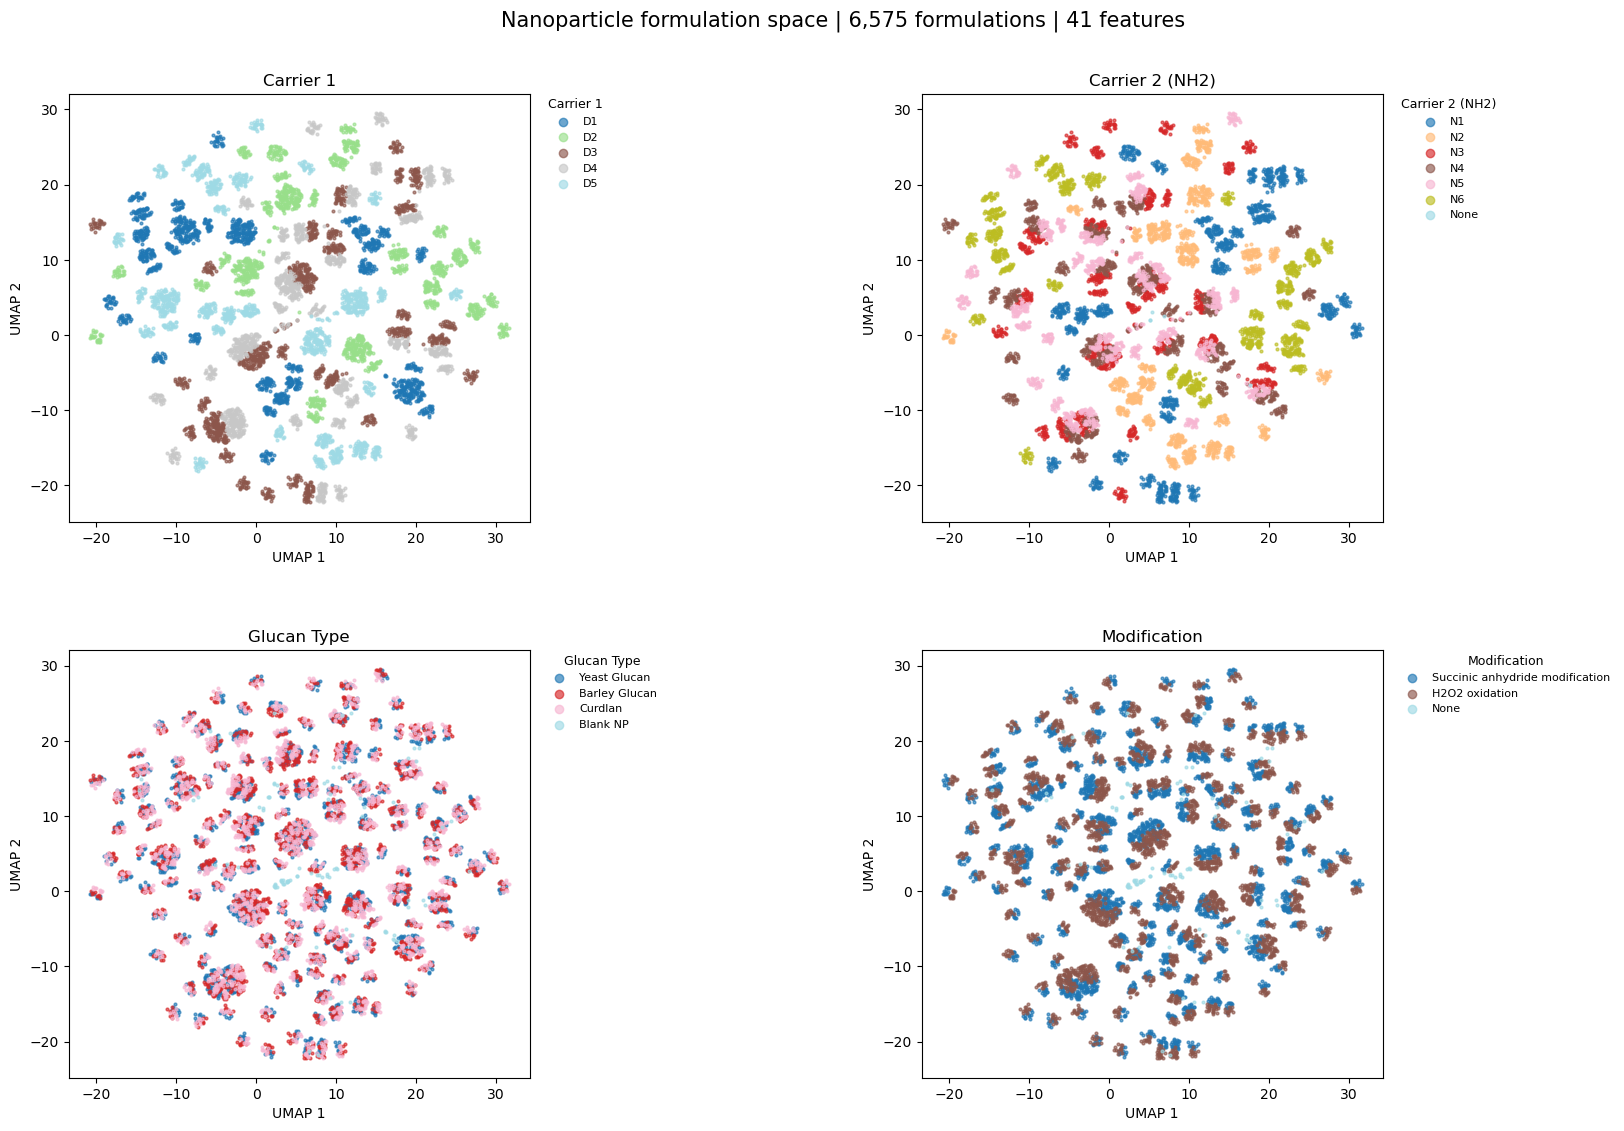

In [34]:
overview_cols = [
    col for col in [
        "Carrier 1",
        "Carrier 2 (NH2)",
        "Glucan Type",
        "Modification",
    ]
    if col in result.columns
]

if overview_cols:
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    # Reserve consistent space for axes and legends.
    fig.subplots_adjust(
        left=0.07,
        right=0.80,
        bottom=0.08,
        top=0.90,
        wspace=0.85,
        hspace=0.30,
    )

    # Use identical coordinate limits in every panel.
    x_min, x_max = result["UMAP_1"].min(), result["UMAP_1"].max()
    y_min, y_max = result["UMAP_2"].min(), result["UMAP_2"].max()

    x_pad = max((x_max - x_min) * 0.05, 0.1)
    y_pad = max((y_max - y_min) * 0.05, 0.1)

    for ax, col in zip(axes.flat, overview_cols):
        labels = result[col].fillna("None").astype(str)
        categories = get_legend_order(labels, col)
        cmap = plt.get_cmap("tab20", max(len(categories), 1))

        for i, category in enumerate(categories):
            mask = labels == category

            ax.scatter(
                result.loc[mask, "UMAP_1"],
                result.loc[mask, "UMAP_2"],
                s=4,
                alpha=0.65,
                color=cmap(i),
                label=category,
                rasterized=True,
            )

        ax.set(
            title=col,
            xlabel="UMAP 1",
            ylabel="UMAP 2",
            xlim=(x_min - x_pad, x_max + x_pad),
            ylim=(y_min - y_pad, y_max + y_pad),
        )

        ax.legend(
            title=col,
            fontsize=8,
            title_fontsize=9,
            markerscale=3,
            bbox_to_anchor=(1.03, 1),
            loc="upper left",
            borderaxespad=0,
            frameon=False,
        )

    for ax in list(axes.flat)[len(overview_cols):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Nanoparticle formulation space | "
        f"{len(result):,} formulations | {X.shape[1]} features",
        fontsize=15,
        y=0.97,
    )

    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

    # Preserve the fixed canvas dimensions.
    fig.savefig(FIGURE_DIR / "umap_overview.png", dpi=200)
    fig.savefig(FIGURE_DIR / "umap_overview.pdf")

    plt.show()
    plt.close(fig)


## Create an interactive plot

Create an optional Plotly scatter plot with formulation IDs and available metadata displayed on hover. Carrier 1 is used for coloring when available.

Export a standalone HTML file with embedded Plotly resources for offline viewing. If Plotly is unavailable, the notebook skips this step and displays installation instructions.


In [35]:
try:
    import plotly.express as px
except ImportError:
    print("Optional interactive plot: install plotly with %pip install plotly")
else:
    interactive = result.copy()
    color_col = "Carrier 1" if "Carrier 1" in interactive else None
    if color_col:
        interactive[color_col] = interactive[color_col].fillna("None")
    fig = px.scatter(interactive, x="UMAP_1", y="UMAP_2", color=color_col,
                     hover_name="ID", hover_data=[c for c in label_cols if c in interactive],
                     title=f"Formulation design space — {FEATURE_SET}", template="simple_white")
    fig.write_html(RESULT_DIR / "umap_interactive.html", include_plotlyjs=True)
    fig.show()
